# Simulation and model smoke test

The simulator returns a dict whose top-level keys can be passed directly to `model_coupling`.


In [1]:
import jax
import matplotlib.pyplot as plt
import numpy as np
import numpyro
from coupling_sources.core.data import StimulusSpec
from coupling_sources.core.model import model_coupling
from coupling_sources.core.priors import coupling_parameter_sites
from coupling_sources.core.simulator import simulate_coupling
from coupling_sources.core.stimuli import generate_stimulus

In [2]:
numpyro.set_host_device_count(4)
numpyro.set_platform("cpu")

In [3]:
stimuli = generate_stimulus(
    StimulusSpec(
        seed=101,
        n_sources=4,
        n_rounds=2,
        n_trials_full=4,
        n_trials_partial=2,
        sigma=0.55,
        lam=0.8,
        coupled_sources=(0, 1),
    )
)

simulation = simulate_coupling(
    seed=201,
    batch=stimuli,
    parameters={"alpha": 0.2, "beta_y": 1.0, "beta_z": 1.0, "kappa": 8.0},
)
simulation.visible_reports.shape, simulation.responses.shape

((1, 2, 6, 4), (1, 2, 6))

In [4]:
seeded_model = numpyro.handlers.seed(model_coupling, jax.random.PRNGKey(0))
seeded_model(simulation)
"model ran"

'model ran'

## Render the model with three trials

This section creates a minimal three-trial batch and renders the NumPyro model graph against it.


visible_reports shape: (1, 1, 3, 4)


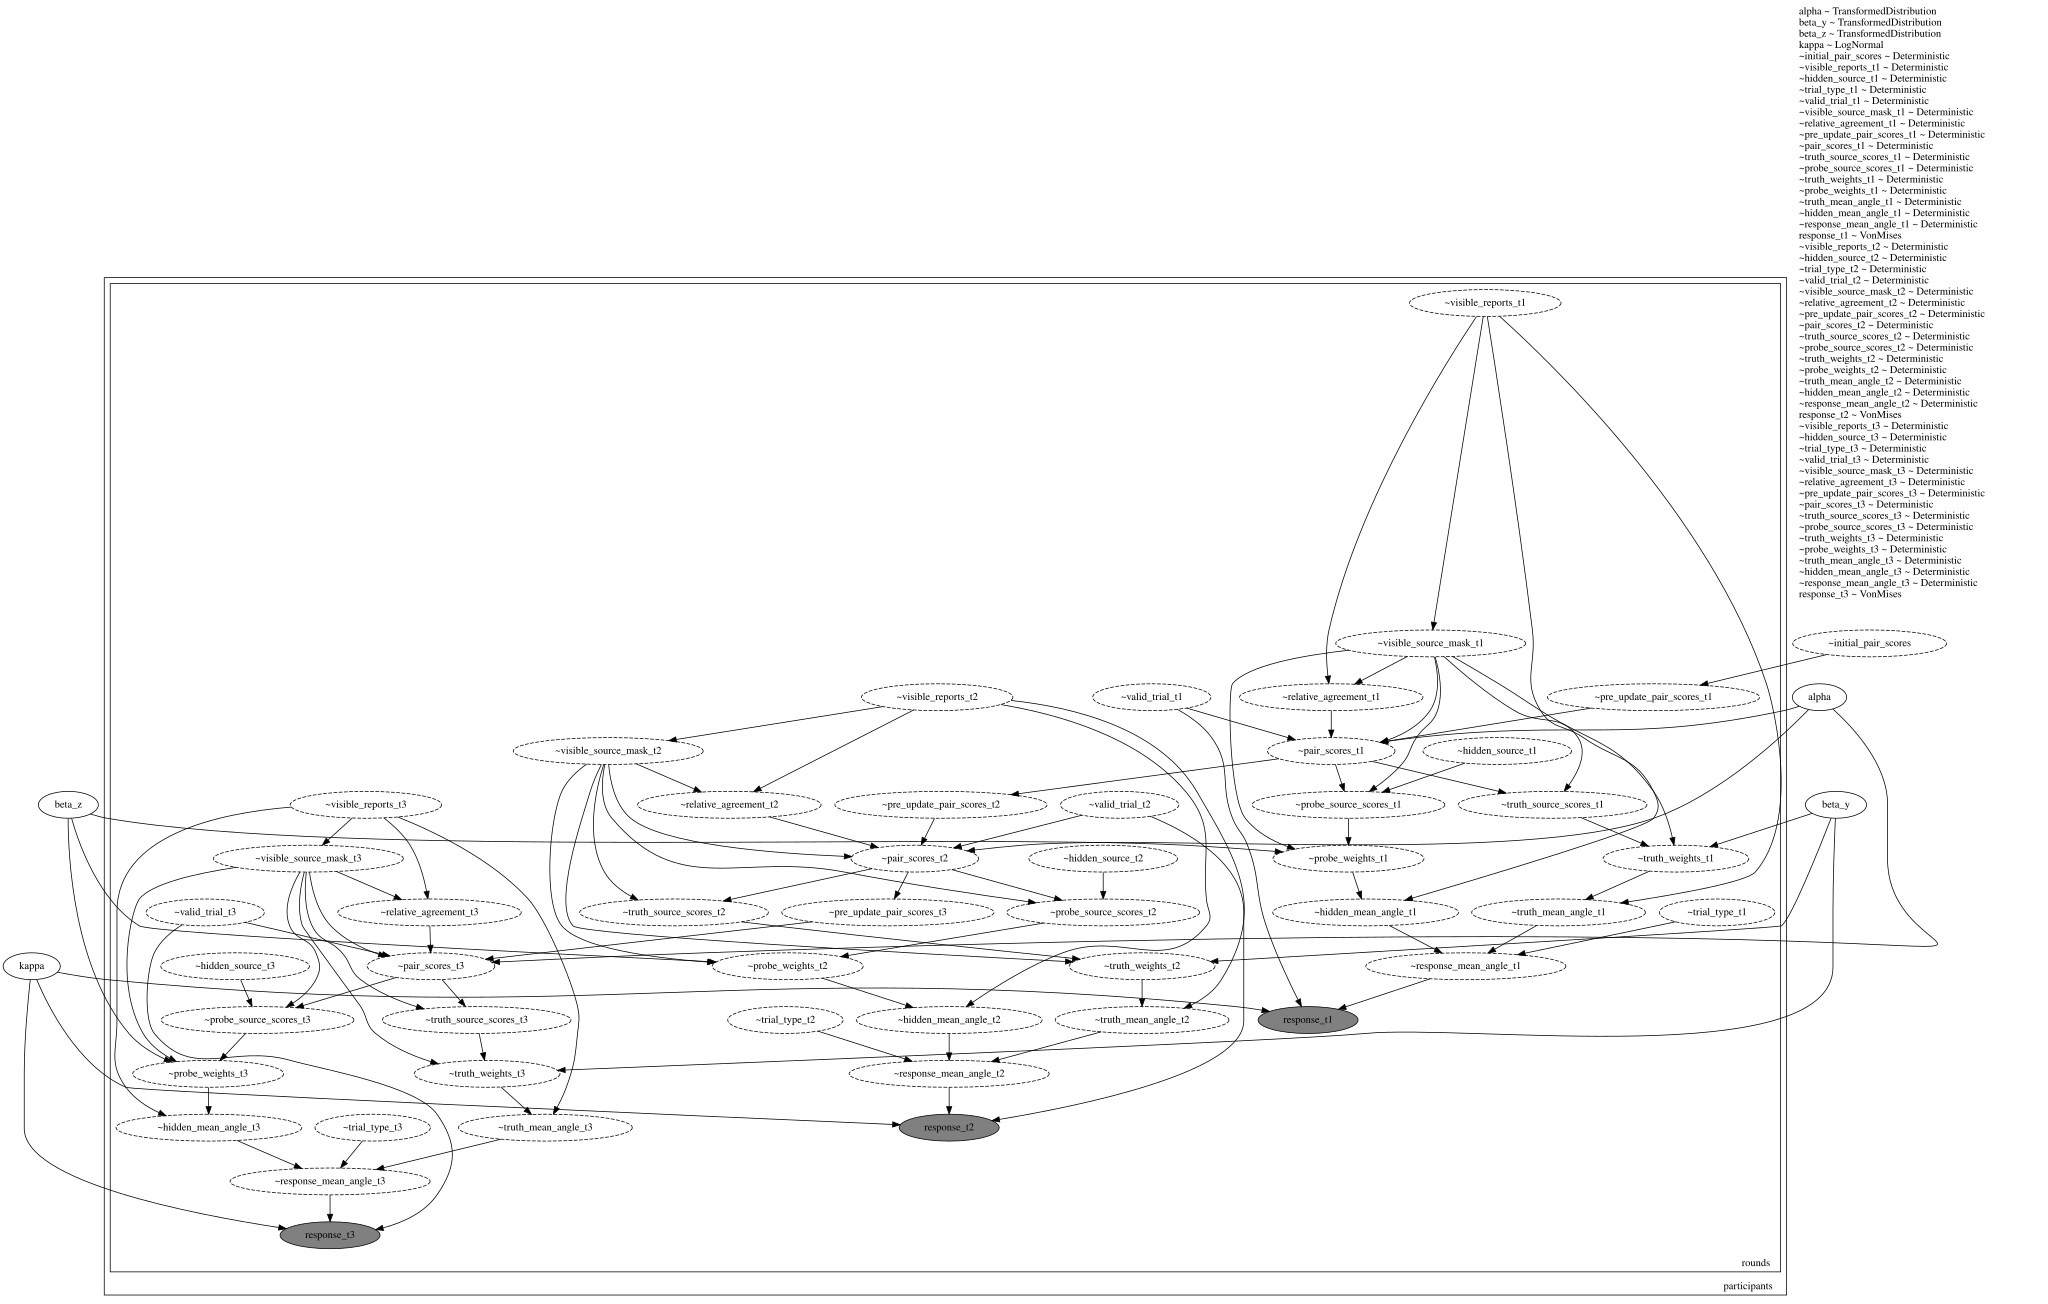

In [5]:
N_RENDER_TRIALS = 3

render_stimuli = generate_stimulus(
    StimulusSpec(
        seed=301,
        n_sources=4,
        n_rounds=1,
        n_trials_full=N_RENDER_TRIALS - 1,
        n_trials_partial=1,
        sigma=0.55,
        lam=0.8,
        coupled_sources=(0, 1),
    )
)

render_simulation = simulate_coupling(
    seed=302,
    batch=render_stimuli,
    parameters={"alpha": 0.2, "beta_y": 1.0, "beta_z": 1.0, "kappa": 16.0},
)

print("visible_reports shape:", render_simulation.visible_reports.shape)
numpyro.render_model(
    model_coupling,
    model_args=(render_simulation,),
    render_distributions=True,
)

## Stimuli, simulation, MCMC fit, and posterior recovery

This section runs the full workflow explicitly: generate stimuli, simulate responses from known parameters, fit the model with MCMC, then overlay posterior distributions with the ground-truth parameter values.


In [6]:
PARAMETER_SITES = coupling_parameter_sites()
GROUND_TRUTH = {"alpha": 0.35, "beta_y": 1.2, "beta_z": 0.8, "kappa": 6.0}

fit_stimuli = generate_stimulus(
    StimulusSpec(
        seed=401,
        n_sources=4,
        n_rounds=1,
        n_trials_full=400,
        n_trials_partial=200,
        sigma=0.55,
        lam=0.8,
        coupled_sources=(0, 1),
    )
)

fit_stimuli.visible_reports.shape

(1, 1, 600, 4)

In [7]:
fit_simulation = simulate_coupling(
    seed=402,
    batch=fit_stimuli,
    parameters=GROUND_TRUTH,
)

fit_simulation.responses.shape

(1, 1, 600)

In [ ]:
kernel = numpyro.infer.NUTS(
    model_coupling,
    target_accept_prob=0.8,
    max_tree_depth=8,
)
mcmc = numpyro.infer.MCMC(
    kernel,
    num_warmup=300,
    num_samples=800,
    num_chains=4,
    progress_bar=True,
)
mcmc.run(
    jax.random.PRNGKey(403),
    fit_simulation,
    extra_fields=("diverging",),
)

posterior_samples = {
    name: np.asarray(values).reshape(-1)
    for name, values in mcmc.get_samples().items()
    if name in PARAMETER_SITES
}
mcmc.print_summary()
print("divergences:", int(np.asarray(mcmc.get_extra_fields()["diverging"]).sum()))

  0%|          | 0/1100 [00:00<?, ?it/s]

  0%|          | 0/1100 [00:00<?, ?it/s]

  0%|          | 0/1100 [00:00<?, ?it/s]

  0%|          | 0/1100 [00:00<?, ?it/s]

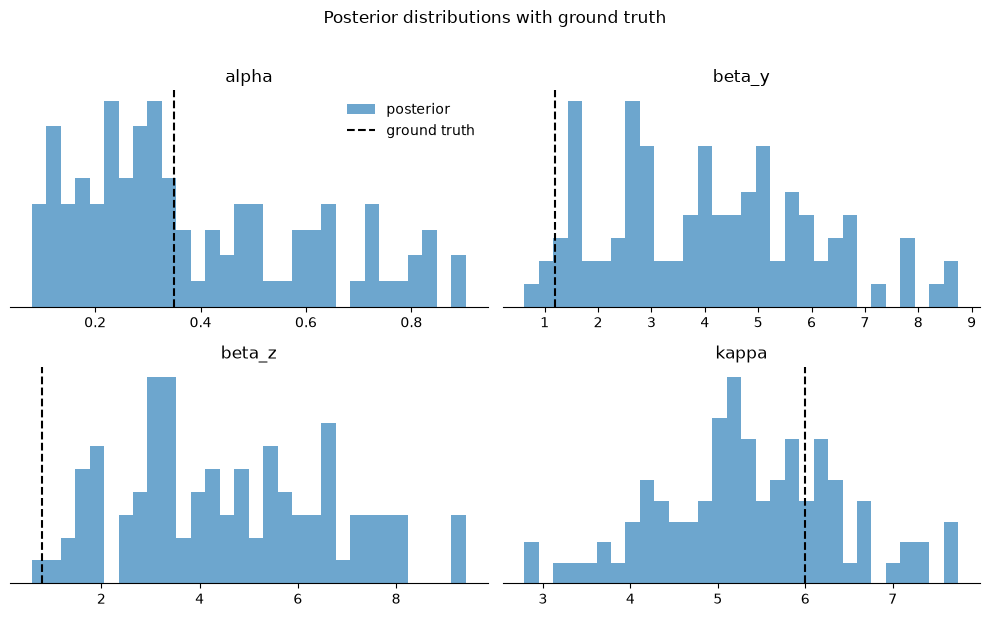

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for ax, parameter in zip(axes.ravel(), PARAMETER_SITES):
    values = posterior_samples[parameter]
    ax.hist(values, bins=30, density=True, alpha=0.65, label="posterior")
    ax.axvline(
        GROUND_TRUTH[parameter],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="ground truth",
    )
    ax.set_title(parameter)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)

axes[0, 0].legend(frameon=False)
fig.suptitle("Posterior distributions with ground truth", y=1.02)
fig.tight_layout()
plt.show()